In [1]:
%pylab inline

%pylab is deprecated, use %matplotlib inline and import the required libraries.
Populating the interactive namespace from numpy and matplotlib


In [2]:
import sklearn

In [5]:
import pandas as pd

In [39]:


#/Users/au261214/Documents/HIH/IML/BDA/BDA2017/data
root = '/Users/au261214/Documents/HIH/IML/BDA/BDA2017/data/'
def read_energi_data(f):
    with open(root+f,encoding='8859') as f:
        col = []
        l=f.readline().strip()
        while l:
            col.append(' '.join(l.split()[1:]))
            l=f.readline().strip()
        
        dat = pd.read_csv(f,sep=';', skipinitialspace=True,lineterminator ='\n')
        dat = dat.drop(columns=dat.columns[-1])
        
        dat.columns = [dat.columns[0]] + col 
        dat = dat.set_index(dat.columns[0])
    return dat



In [40]:
energi = read_energi_data('20161208_onlinedata.csv')
co2 = energi['CO2 udledning']
energi

,Centrale kraftværker DK1,Centrale kraftværker DK2,Decentrale kraftværker DK1,Decentrale kraftværker DK2,Vindmøller DK1,Vindmøller DK2,Udveksling Jylland-Norge,Udveksling Jylland-Sverige,Udveksling Jylland-Tyskland,Udveksling Sjælland-Sverige,Udveksling Sjælland-Tyskland,Udveksling Bornholm-Sverige,Udveksling Fyn-Sjaelland,Temperatur i Malling,Vindhastighed i Malling,CO2 udledning,Havmøller DK,Landmøller DK,Solceller DK1,Solceller DK2
Dato og tid,,,,,,,,,,,,,,,,,,,,
2016-12-08 00:00,599,587,270,139,2721,733,-1527,-338,554,-669,113,-18,-381,10,9,190,1060,2394,0,0
2016-12-08 00:05,557,583,271,126,2757,732,-1508,-330,505,-726,247,-17,-318,10,11,184,1058,2430,0,0
2016-12-08 00:10,527,590,241,117,2746,742,-1516,-322,473,-734,304,-19,-256,10,11,180,1061,2427,0,0
2016-12-08 00:15,512,577,213,116,2750,741,-1518,-314,483,-670,304,-18,-193,10,9,175,1060,2431,0,0
2016-12-08 00:20,492,568,198,115,2759,749,-1520,-313,503,-668,304,-18,-192,10,8,170,1060,2448,0,0
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
2016-12-08 23:35,844,616,322,181,1324,648,-983,189,521,-23,-316,-14,-219,8,7,292,856,1116,0,0
2016-12-08 23:40,848,615,324,182,1310,636,-984,189,511,-28,-316,-15,-219,8,10,294,842,1104,0,0
2016-12-08 23:45,848,613,322,179,1297,600,-986,150,550,0,-316,-15,-220,8,7,297,807,1090,0,0


In [9]:
energi=energi.drop(['Temperatur i Malling','Vindhastighed i Malling'],axis=1)
energi=energi.drop('CO2 udledning',axis=1)
energi=energi.drop('Havmøller DK',axis=1)
energi=energi.drop('Landmøller DK',axis=1)

In [17]:
from sklearn.svm import SVR

In [18]:
svr_model = SVR(kernel='linear')
svr_model_non = SVR(kernel='rbf')

In [19]:
svr_model.fit(energi,co2)
svr_model_non.fit(energi,co2)

SVR()

In [20]:
predict = svr_model.predict(energi)
predict_non = svr_model_non.predict(energi)

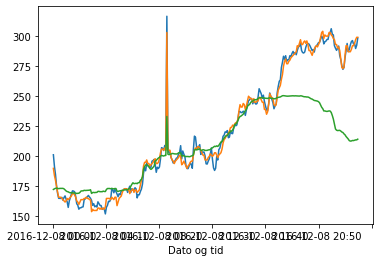

In [21]:
plot(predict)
co2.plot()
plot(predict_non)

In [22]:
svr_model.score(energi,co2)

0.9922806916061307

In [23]:
svr_model_non.score(energi,co2)

0.6466007781871317

In [28]:
from sklearn.ensemble import RandomForestRegressor,ExtraTreesRegressor

In [29]:
forest_model = RandomForestRegressor(n_estimators=30,max_features=15)
forest_model_sekventiel = RandomForestRegressor(n_estimators=30,max_features=15)
forest_model_random = RandomForestRegressor(n_estimators=30,max_features=15)

In [30]:
end = len(co2)//4
train = np.random.randint(0,len(co2)-1,end)
co2_train = co2.iloc[train]
energi_train = energi.iloc[train]

co2_train_sek = co2[:end]
energi_train_sek = energi[:end]

forest_model_random.fit(energi_train,co2_train)
forest_model_sekventiel.fit(energi_train_sek,co2_train_sek)
forest_model.fit(energi,co2)

,n_estimators,30
,criterion,'squared_error'
,max_depth,None
,min_samples_split,2
,min_samples_leaf,1
,min_weight_fraction_leaf,0.0
,max_features,15
,max_leaf_nodes,None
,min_impurity_decrease,0.0
,bootstrap,True
,oob_score,False


In [31]:
forest = forest_model.predict(energi)
forest_sekventiel = forest_model_sekventiel.predict(energi)
forest_random = forest_model_random.predict(energi)

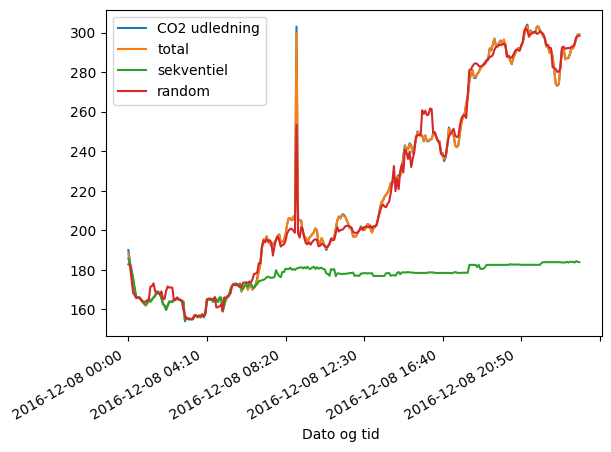

In [32]:
fig = co2.plot()
plot(forest,label='total')
plot(forest_sekventiel,label='sekventiel')
plot(forest_random,label='random')
legend()
fig.figure.autofmt_xdate()


In [33]:
forest_model.score(energi,co2)

0.9999154338136733

In [34]:
forest_model_random.score(energi,co2)

0.9897825768331078

In [35]:
forest_model_sekventiel.score(energi,co2)

-0.6141311411818313

In [36]:
pwd

'/Users/au261214/Documents/HIH/IML/notebooks/notebooks'

In [37]:
!uv add --active xgboost


Resolved 175 packages in 883ms                                       
Prepared 1 package in 244ms                                              ⠋ Preparing packages... (0/0)                                                   
Uninstalled 1 package in 25ms
Installed 2 packages in 14ms                                
 ~ grpcio==1.67.0
 + xgboost==3.2.0


In [38]:
from xgboost import XGBoostRegressor

XGBoostError: 
XGBoost Library (libxgboost.dylib) could not be loaded.
Likely causes:
  * OpenMP runtime is not installed
    - vcomp140.dll or libgomp-1.dll for Windows
    - libomp.dylib for Mac OSX
    - libgomp.so for Linux and other UNIX-like OSes
    Mac OSX users: Run `brew install libomp` to install OpenMP runtime.

  * You are running 32-bit Python on a 64-bit OS

Error message(s): ["dlopen(/Users/au261214/Documents/HIH/IML/notebooks/.venv/lib/python3.10/site-packages/xgboost/lib/libxgboost.dylib, 0x0006): Library not loaded: @rpath/libomp.dylib\n  Referenced from: <1A0D8152-BF46-3BE0-B651-EE965C187777> /Users/au261214/Documents/HIH/IML/notebooks/.venv/lib/python3.10/site-packages/xgboost/lib/libxgboost.dylib\n  Reason: tried: '/opt/homebrew/opt/libomp/lib/libomp.dylib' (no such file), '/System/Volumes/Preboot/Cryptexes/OS/opt/homebrew/opt/libomp/lib/libomp.dylib' (no such file), '/opt/homebrew/opt/libomp/lib/libomp.dylib' (no such file), '/System/Volumes/Preboot/Cryptexes/OS/

In [42]:
24*18*10*8*1440/10**9*740

36.827136

In [37]:
16E6/1440/740

15.015015015015015